<a href="https://colab.research.google.com/github/sahilbharti1601/india-ecommerce-sales-analysis/blob/main/india_ecommerce_sales_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("amazon_sales_2025_INR-selected-columns.csv", encoding="unicode_escape")

print("Rows and columns:", df.shape)
df.info()
df.head()

Rows and columns: (15000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          15000 non-null  object 
 1   Date              15000 non-null  object 
 2   Customer_ID       15000 non-null  object 
 3   Product_Category  15000 non-null  object 
 4   Product_Name      15000 non-null  object 
 5   Quantity          15000 non-null  int64  
 6   Unit_Price_INR    15000 non-null  float64
 7   Total_Sales_INR   15000 non-null  float64
 8   Payment_Method    15000 non-null  object 
 9   Delivery_Status   15000 non-null  object 
dtypes: float64(2), int64(1), object(7)
memory usage: 1.1+ MB


,Order_ID,Date,Customer_ID,Product_Category,Product_Name,Quantity,Unit_Price_INR,Total_Sales_INR,Payment_Method,Delivery_Status
0,ORD100000,2025-01-25,CUST2796,Home & Kitchen,Cookware Set,2,25574.41,51148.82,Credit Card,Returned
1,ORD100001,2025-08-28,CUST9669,Beauty,Hair Dryer,1,19361.41,19361.41,Debit Card,Returned
2,ORD100002,2025-02-27,CUST5808,Electronics,Tablet,3,38476.22,115428.66,Cash on Delivery,Delivered
3,ORD100003,2025-02-24,CUST5889,Electronics,Headphones,5,38145.72,190728.60,Credit Card,Delivered
4,ORD100004,2025-06-15,CUST9005,Clothing,Saree,5,45940.98,229704.90,UPI,Delivered


## Data Cleaning

In [4]:
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

# Convert Date from text to a real date
df["Date"] = pd.to_datetime(df["Date"])

# Check that Quantity x Unit Price = Total Sales on every row
diff = (df["Quantity"] * df["Unit_Price_INR"] - df["Total_Sales_INR"]).abs().max()
print("Largest mismatch in Total Sales:", round(diff, 2))

Missing values:
 Order_ID            0
Date                0
Customer_ID         0
Product_Category    0
Product_Name        0
Quantity            0
Unit_Price_INR      0
Total_Sales_INR     0
Payment_Method      0
Delivery_Status     0
dtype: int64
Duplicate rows: 0
Largest mismatch in Total Sales: 0.0


## 1. Business Overview

In [5]:
print("Total revenue (₹ crore):", round(df["Total_Sales_INR"].sum() / 1e7, 2))
print("Total orders:", df["Order_ID"].nunique())
print("Unique customers:", df["Customer_ID"].nunique())
print("Average order value (₹):", round(df["Total_Sales_INR"].mean()))

Total revenue (₹ crore): 111.82
Total orders: 15000
Unique customers: 7259
Average order value (₹): 74544


**Insight:** The store generated ₹111.8 crore from 15,000 orders placed by 7,259 customers. The average order value is about ₹74,500, which is high for general e-commerce — more on this in the data quality note below.

## 2. Monthly Sales Trend — Is there a Diwali spike?

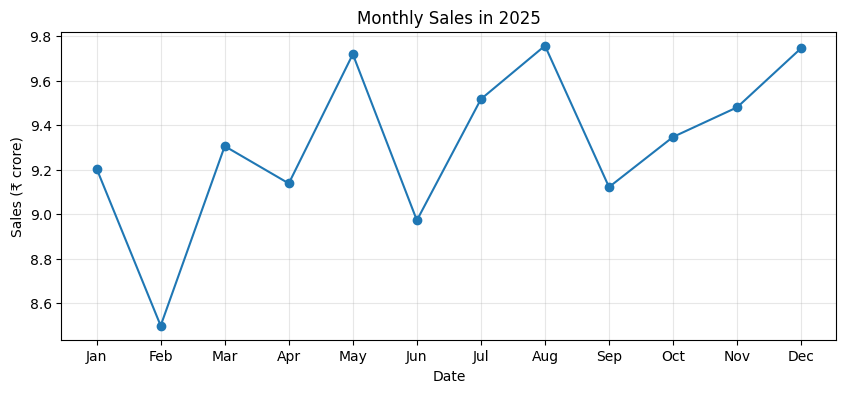

In [6]:
monthly = df.groupby(df["Date"].dt.month)["Total_Sales_INR"].sum() / 1e7
plt.figure(figsize=(10, 4))
monthly.plot(marker="o")
plt.xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
plt.title("Monthly Sales in 2025")
plt.ylabel("Sales (₹ crore)")
plt.grid(alpha=0.3)
plt.show()

**Insight:** Sales are flat throughout 2025, ranging only from ₹8.5 to ₹9.8 crore per month. There is no Diwali spike: sales during the festive window (late September to October) were actually slightly *below* the yearly average. In real Indian e-commerce, festive sales typically show a large jump, so this suggests the dataset is synthetic.

## 3. Sales by Product Category

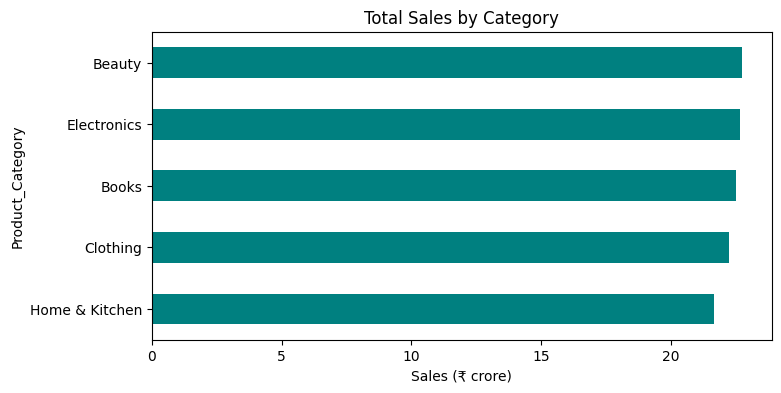

In [7]:
cat = (df.groupby("Product_Category")["Total_Sales_INR"].sum() / 1e7).sort_values()
cat.plot(kind="barh", figsize=(8, 4), color="teal")
plt.title("Total Sales by Category")
plt.xlabel("Sales (₹ crore)")
plt.show()

**Insight:** All five categories contribute almost equally (₹21.7–22.8 crore each). Beauty leads narrowly and Home & Kitchen is lowest, but the gap is only about 5%, so no category clearly dominates.

## 4. Payment Methods and Returns

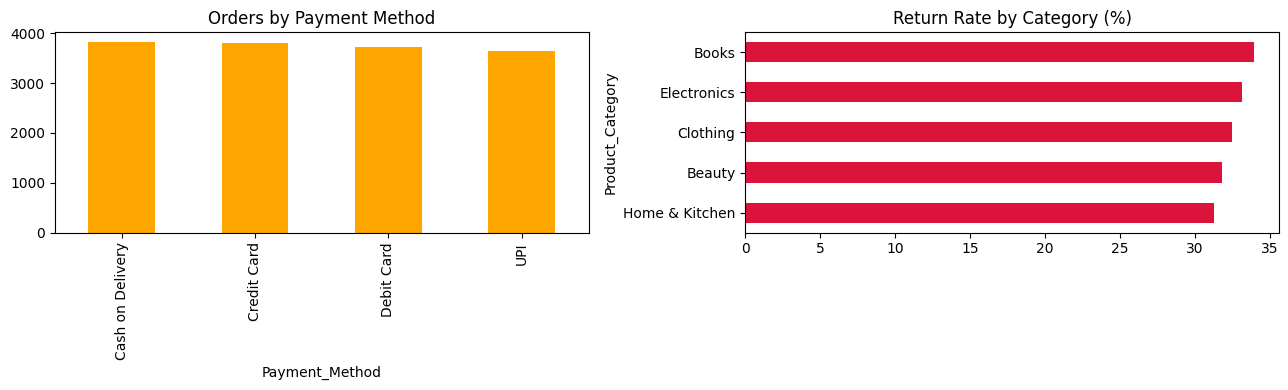

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

df["Payment_Method"].value_counts().plot(kind="bar", ax=ax[0], color="orange")
ax[0].set_title("Orders by Payment Method")

returns = pd.crosstab(df["Product_Category"], df["Delivery_Status"], normalize="index") * 100
returns["Returned"].sort_values().plot(kind="barh", ax=ax[1], color="crimson")
ax[1].set_title("Return Rate by Category (%)")

plt.tight_layout()
plt.show()

**Insight:** Each payment method accounts for roughly 25% of orders. Return rates are 31–34% in every category, far higher than typical e-commerce return rates. If this were real data, returns would be the most urgent issue for the business to investigate.

## Conclusion

- The data is clean: no missing values, no duplicates, and all sales totals are consistent.
- Sales, categories and payment methods are all spread almost perfectly evenly, with no seasonal or festive patterns.
- Unit prices are random across products (e.g. a comic book priced at ~₹50,000), and one-third of all orders are returned.

**Data quality finding:** These patterns indicate the dataset is synthetically generated rather than real transaction data. A key part of analysis is validating data before drawing business conclusions — in a real setting, I would flag this to the data owner before using it for decisions.

**Next steps:** Apply the same analysis to real festive-season sales data to measure the actual Diwali effect, identify top-performing customer segments, and investigate return drivers.